**Observação metodológica importante:** O experimento demonstrativo **4C2 é treinado com CVaR 50%**, e não 10%. Para seis estados com Dicke uniforme, a melhor carteira já aparece com probabilidade 16,67%; portanto, o CVaR inferior de 10% da distribuição ideal nasce saturado no ótimo. CVaR 50% fornece um gradiente informativo. **Os experimentos multicardinais anteriores permanecem baseados em CVaR 10%.** Este notebook serve para explicar treinamento em um problema pequeno, não para reproduzir literalmente a hiperparametrização otimizada para problemas maiores.

# G5.38 — 4C2 ponta a ponta: dados reais, treinamento e inferência one-forward

**Demonstração didática com treinamento próprio.** Este notebook vai desde a coleta de preços do Yahoo Finance até a atualização efetiva dos pesos do Transformer, a validação em 2024 e os testes retrospectivos em 2025–2026.

- **Engenharia de dados:** preços → retornos → $\mu$ e $\Sigma$ → 32 carteiras de contexto → 18 atributos por gate.
- **Circuito de Dicke:** quatro gates parametrizados, iniciando com distribuição uniforme sobre as seis carteiras de 4C2.
- **Treinamento real:** CVaR 50% medido com shots (ajuste exclusivo para 4C2) → gradiente SPSA → alvo local *stop-gradient* → MSE → `backward()` → `AdamW.step()`.
- **Avaliação:** comparar Dicke e rede **antes/depois**, identificar bitstring ótimo por enumeração apenas para auditoria, e testar anos posteriores.

**O modelo prevê quatro ângulos conjuntamente em um único forward; não aprende uma carteira ótima supervisionada.** Cada execução do circuito aplica os quatro gates sequencialmente. Os preços devem ser baixados em seu computador com acesso à internet; se o Yahoo estiver indisponível, é utilizado somente um CSV previamente salvo e identificado.

> **Escopo científico:** 4C2 tem apenas 6 carteiras. É excelente para demonstrar o mecanismo, mas não prova escalabilidade nem vantagem quântica. As janelas de treino sobrepostas também não são observações independentes.

## Bloco A — Engenharia de dados

É aqui que transformamos séries financeiras em **variáveis físicas e estatísticas** utilizáveis pela arquitetura. Nenhuma carteira ótima é utilizada para ajustar pesos neste notebook.

### A1. Bibliotecas e ambiente

**Entrada:** ambiente Python com `numpy`, `pandas`, `matplotlib`, `torch`, `yfinance` e `qiskit`.

**Processamento:** importar as bibliotecas e conferir dependências.

**Saída:** objetos e funções para as etapas seguintes. Se necessário, instale antes em uma célula do Jupyter: `%pip install yfinance qiskit`.

In [14]:
from pathlib import Path
from itertools import combinations
import hashlib
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import yfinance as yf
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from IPython.display import display

### A2. Configuração explícita do exemplo 4C2

**Entrada:** nomes de quatro ações negociadas e datas de referência.

**Processamento:** fixar o período dos históricos e separar as datas para desenvolvimento e avaliação.

**Saída:** uma configuração reproduzível, sem variáveis escondidas e sem “modo piloto”.

**Separação:** datas de ancoragem de **2024 até julho** para construir o normalizador didático; **agosto–setembro de 2024** para validação; **2025 e 2026** somente para avaliação retrospectiva. Um Hamiltoniano é estimado com preços **até a sua própria data**; não usamos preços posteriores ao cenário avaliado.

In [15]:
ATIVOS = {'A': 'AAPL', 'B': 'MSFT', 'C': 'JPM', 'D': 'JNJ'}
TICKERS = list(ATIVOS.values())
N, K = 4, 2

INICIO = '2023-01-01'              # histórico para estimativas de 2024
FIM_EXCLUSIVO = '2026-10-01'       # inclui até setembro/2026
JANELA_PREGAO = 60               # 60 retornos diários anteriores/até a data
AMOSTRAS_CONTEXTO = 32           # Monte Carlo clássico
SEMENTE = 20261016

PASTA = Path('g538_4c2_dados_yahoo').resolve()
PASTA.mkdir(parents=True, exist_ok=True)
ARQUIVO_CACHE = PASTA / 'precos_ajustados_4c2.csv'

print('Ativos:', ATIVOS, '| qubits:', N, '| escolhidos:', K)

Ativos: {'A': 'AAPL', 'B': 'MSFT', 'C': 'JPM', 'D': 'JNJ'} | qubits: 4 | escolhidos: 2


### A3. Baixar os preços **ajustados** no Yahoo Finance

**Entrada:** `TICKERS`, `INICIO`, `FIM_EXCLUSIVO`.

**Processamento:** `yfinance.download` coleta preços históricos (ajustados por desdobramentos e dividendos quando disponíveis via `auto_adjust=True`). O código trata as duas organizações possíveis de colunas do Yahoo (`MultiIndex`).

**Saída:** tabela com **datas nas linhas** e as **quatro ações nas colunas**; salva em CSV para reutilização.

Se o download falhar, **não são criados preços artificiais**. Um arquivo em cache gerado anteriormente poderá ser reutilizado, com aviso explícito.

In [16]:
def baixar_precos(tickers, inicio, fim, cache):
    tabela = yf.download(tickers, start=inicio, end=fim, auto_adjust=True,
                         progress=False, threads=False, group_by='column')
    if tabela is None or tabela.empty:
        raise RuntimeError('Yahoo Finance devolveu tabela vazia')
    tabela = tabela['Close'][tickers]
    tabela.to_csv(cache)
    print('Origem: Yahoo Finance; cache criado:', cache)
    return tabela


### A4. Executar a coleta e conferir o intervalo

**Entrada:** função de download acima.

**Processamento:** obter a tabela e verificar dimensão, primeiras/últimas datas e identificação das colunas.

**Saída:** `precos_brutos`. Este bloco não altera as observações.

In [17]:
precos_brutos = baixar_precos(TICKERS, INICIO, FIM_EXCLUSIVO, ARQUIVO_CACHE)
precos_brutos.index = pd.to_datetime(precos_brutos.index).tz_localize(None)
print('Formato:', precos_brutos.shape)
print('Período:', precos_brutos.index.min(), 'até', precos_brutos.index.max())
display(precos_brutos.head(4))

Origem: Yahoo Finance; cache criado: C:\Users\Marlon\Downloads\g538_4c2_dados_yahoo\precos_ajustados_4c2.csv
Formato: (939, 4)
Período: 2023-01-03 00:00:00 até 2026-09-30 00:00:00


Ticker,AAPL,MSFT,JPM,JNJ
Date,,,,
2023-01-03,122.876740,232.510559,123.120956,160.081070
2023-01-04,124.144112,222.339798,124.269066,161.823929
2023-01-05,122.827606,215.750168,124.241508,160.629074
2023-01-06,127.346962,218.292862,126.618950,161.931747


### A5. Limpeza e controle de qualidade

**Entrada:** preços retornados pelo Yahoo Finance.

**Processamento:** ordenar as datas, eliminar datas duplicadas, converter tudo para números e rejeitar preços inválidos. Uma data com preço ausente em qualquer ação é descartada, sem preenchimento artificial.

**Saída:** `precos`, uma matriz positiva, finita e alinhada para os quatro ativos.

In [18]:
precos = precos_brutos.sort_index()
precos = precos.loc[~precos.index.duplicated(keep='last'), TICKERS]
precos = precos.apply(pd.to_numeric, errors='coerce')
precos = precos.where(precos > 0).dropna(how='any')
if len(precos) < 180:
    raise ValueError(f'Histórico insuficiente após limpeza: {len(precos)} pregões')
print('Pregões completos:', len(precos))
print('Primeiro e último:', precos.index.min().date(), precos.index.max().date())

Pregões completos: 939
Primeiro e último: 2023-01-03 2026-09-30


### A6. Gráfico de inspeção dos preços

**Entrada:** `precos`.

**Processamento:** dividir cada série por seu primeiro preço, para começar todas em 100. A transformação é **apenas para o gráfico**.

**Saída:** gráfico legível mesmo quando as ações possuem preços de magnitudes muito diferentes.

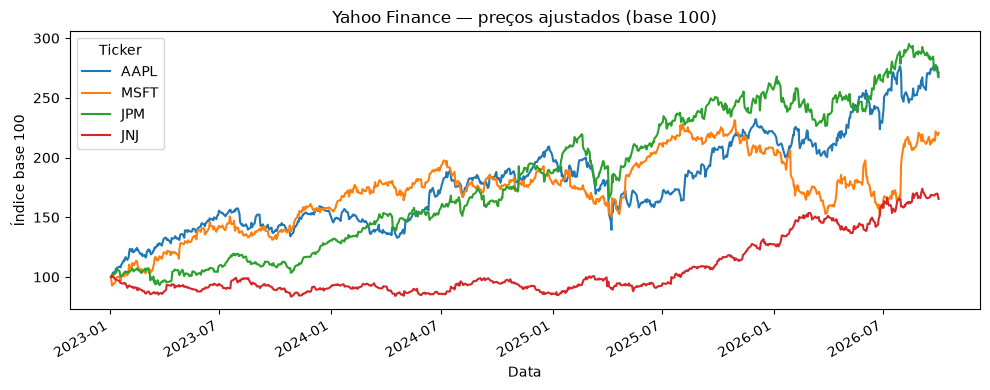

In [19]:
precos_base100 = 100 * precos / precos.iloc[0]
ax = precos_base100.plot(figsize=(10, 4), linewidth=1.5)
ax.set(title='Yahoo Finance — preços ajustados (base 100)',
       xlabel='Data', ylabel='Índice base 100')
plt.tight_layout()
plt.show()

### A7. Calcular retornos diários

**Entrada:** sequência $P_{t,i}$ de preços do ativo $i$.

**Processamento:** retorno simples $r_{t,i}=P_{t,i}/P_{t-1,i}-1$.

**Saída:** tabela `RET`: em cada linha, quatro retornos diários; é dessa tabela que estimamos $\mu$ e $\Sigma$.

A primeira data de retorno fica vazia por não haver fechamento anterior e será descartada.

In [22]:
RET = precos.pct_change(fill_method=None)
RET = RET.replace([np.inf, -np.inf], np.nan).dropna(how='any')
print('Dimensão dos retornos:', RET.shape)
display(RET.head(4))

Dimensão dos retornos: (938, 4)


Ticker,AAPL,MSFT,JPM,JNJ
Date,,,,
2023-01-04,0.010314,-0.043743,0.009325,0.010887
2023-01-05,-0.010605,-0.029638,-0.000222,-0.007384
2023-01-06,0.036794,0.011785,0.019136,0.008110
2023-01-09,0.004089,0.009736,-0.004132,-0.025909


### A8. Separação temporal: quais datas cada parte pode consultar?

**Entrada:** série diária de retornos já limpa. **Processamento:** construir diversas instâncias de 4C2 em datas progressivas, sempre usando **somente os 60 retornos até a âncora**, sem olhar preços futuros.

- **Treino:** uma instância a cada dois dias úteis, de março a julho de 2024. As variações de $\mu$ e $\Sigma$ ensinam a rede a lidar com problemas diferentes, sem trocar os quatro ativos.
- **Validação:** datas semanais de agosto e setembro de 2024. Usada apenas para selecionar o checkpoint.
- **Testes:** junho/dezembro de 2025 e junho/setembro de 2026. Só serão consultados depois que a rede terminar de treinar.

As datas são **datas-limite de informação**, não exemplos rotulados com ângulos ótimos.

In [23]:
ANCORAS = {
    # Vários Hamiltonianos distintos, todos montados com histórico disponível em 2024.
    'treino_2024': pd.bdate_range('2024-03-01', '2024-07-31', freq='2B').strftime('%Y-%m-%d').tolist(),
    'validacao_2024': pd.date_range('2024-08-02', '2024-09-27', freq='W-FRI').strftime('%Y-%m-%d').tolist(),
    'teste_2025': ['2025-06-30', '2025-12-30'],
    'teste_2026': ['2026-06-30', '2026-09-30'],
}

pd.DataFrame([(g, d) for g, dates in ANCORAS.items() for d in dates],
             columns=['grupo', 'data_referencia']).groupby('grupo').agg(
    quantidade=('data_referencia', 'size'),
    primeira=('data_referencia', 'min'), ultima=('data_referencia', 'max'))

,quantidade,primeira,ultima
grupo,,,
teste_2025,2,2025-06-30,2025-12-30
teste_2026,2,2026-06-30,2026-09-30
treino_2024,55,2024-03-01,2024-07-31
validacao_2024,9,2024-08-02,2024-09-27


### A9. Transformar os retornos em $\mu$ e $\Sigma$

Para cada data $t$, selecionamos os 60 últimos retornos **observados até $t$**.

- $\mu_i=252\,\overline r_i$: retorno médio anualizado do ativo $i$;
- $\Sigma_{ij}=252\,\operatorname{Cov}(r_i,r_j)$: covariância anualizada dos ativos $i,j$.

**Entrada:** `RET` e uma âncora.

**Saída:** um problema financeiro completo com quatro ativos, vetor $\mu\in\mathbb R^4$ e matriz $\Sigma\in\mathbb R^{4\times4}$. O ano da âncora não entra como rótulo nem como previsão.

In [25]:
def construir_hamiltoniano(grupo, data):
    t = pd.Timestamp(data)
    janela = RET.loc[:t, TICKERS].tail(JANELA_PREGAO)
    if len(janela) < JANELA_PREGAO or (t - janela.index[-1]).days > 10:
        raise ValueError(f'Dados insuficientes ou sem pregão próximo à âncora {data}')
    Sigma = 252 * janela.cov().to_numpy()
    return {'grupo': grupo, 'data': data, 'n': N, 'k': K,
            'mu': 252 * janela.mean().to_numpy(),
            'Sigma': (Sigma + Sigma.T) / 2, 'assets': tuple(TICKERS)}


### A10. Construir todos os cenários temporais

**Entrada:** grupos de datas e função anterior.

**Processamento:** criar um $(\mu,\Sigma)$ diferente para cada âncora.

**Saída:** `INSTANCIAS`, separadas no dicionário `POR_GRUPO`. O modelo mais adiante receberá uma dessas instâncias como entrada.

In [26]:
INSTANCIAS = [construir_hamiltoniano(grupo, data)
              for grupo, datas in ANCORAS.items() for data in datas]
POR_GRUPO = {grupo: [r for r in INSTANCIAS if r['grupo'] == grupo]
             for grupo in ANCORAS}
print('Instâncias por grupo:', {g: len(v) for g, v in POR_GRUPO.items()})

Instâncias por grupo: {'treino_2024': 55, 'validacao_2024': 9, 'teste_2025': 2, 'teste_2026': 2}


### A11. Ver como a matriz de covariância entra no problema

**Entrada:** primeira instância de treinamento de 2024.

**Processamento:** mostrar seus quatro retornos anualizados e a matriz de covariância.

**Saída:** tabela e mapa de calor da relação de risco entre ativos.

Data de referência: 2024-03-01


AAPL   -0.201659
MSFT    0.519095
JPM     0.703543
JNJ     0.123574
Name: mu anualizado, dtype: float64

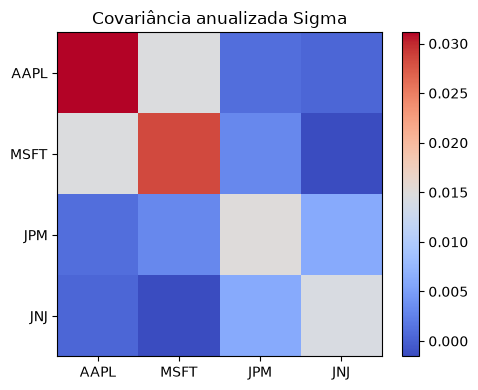

In [27]:
exemplo = POR_GRUPO['treino_2024'][0]
print('Data de referência:', exemplo['data'])
display(pd.Series(exemplo['mu'], index=TICKERS, name='mu anualizado'))
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(exemplo['Sigma'], cmap='coolwarm')
ax.set_xticks(range(N), TICKERS)
ax.set_yticks(range(N), TICKERS)
ax.set_title('Covariância anualizada Sigma')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## Bloco B — Da engenharia financeira aos bitstrings

### B1. Construir as seis escolhas possíveis

O Yahoo Finance não fornece seis carteiras prontas: **nós as construímos**.

$$\binom42=6.$$

**Entrada:** $n=4$, $k=2$.

**Processamento:** combinações de índices sem repetição.

**Saída:** matriz $X\in\{0,1\}^{6\times4}$, na ordem A, B, C, D. Um `1` indica ativo selecionado. A apresentação textual de Qiskit inverte essa ordem.

In [29]:
def carteiras_validas(n, k):
    X = np.zeros((math.comb(n, k), n), dtype=int)
    for linha, indices in enumerate(combinations(range(n), k)):
        X[linha, list(indices)] = 1
    return X

X = carteiras_validas(N, K)
BITS = [''.join(map(str, x)) for x in X]  # convenção financeira: A B C D
display(pd.DataFrame(X, columns=TICKERS, index=BITS))

,AAPL,MSFT,JPM,JNJ
1100,1,1,0,0
1010,1,0,1,0
1001,1,0,0,1
0110,0,1,1,0
0101,0,1,0,1
0011,0,0,1,1


### B2. Função objetivo — identificar a melhor carteira por auditoria

$$E_H(x)=\frac12 x^\top\Sigma x-\mu^\top x.$$

**Entrada:** seis carteiras, retornos esperados e covariâncias do cenário.

**Processamento:** energia/qualidade de cada escolha; menor é melhor.

**Saída:** uma tabela ordenada; como o problema é pequeno, também conseguimos identificar o ótimo clássico verdadeiro. **Essa resposta não faz parte dos 18 atributos da rede.**

In [ ]:
def energias_de_carteiras(X, mu, Sigma):
# Garante que X seja uma matriz do NumPy com números decimais (float) sem duplicar memória
    X = np.asarray(X, dtype=float)
    return 0.5 * np.einsum('bi,ij,bj->b', X, Sigma, X) - X @ mu
    # Calcula 0.5 * X^T * Sigma * X em lote (batch):
    # 'bi,ij,bj': multiplica cada carteira (b) pelos ativos (i, j) de Sigma
    # '-> b': elimina os ativos (soma tudo) e preserva 1 valor de risco por carteira


def tabela_carteiras(r):#calculando a relação de energia classicamente 
    E = energias_de_carteiras(X, r['mu'], r['Sigma'])
    return pd.DataFrame({'bitstring_ABCD': BITS, 'energia': E}).sort_values('energia')

display(tabela_carteiras(exemplo).round(6))

,bitstring_ABCD,energia
3,0110,-1.197926
5,0011,-0.806332
4,0101,-0.622946
1,1010,-0.477754
0,1100,-0.273079
2,1001,0.101237


### B3. Visualização das seis energias

**Entrada:** tabela do bloco anterior.

**Processamento:** ordenar as energias crescentemente.

**Saída:** o melhor bitstring fica visível como a primeira barra. Isso é um **padrão de comparação**, não um rótulo de treino.

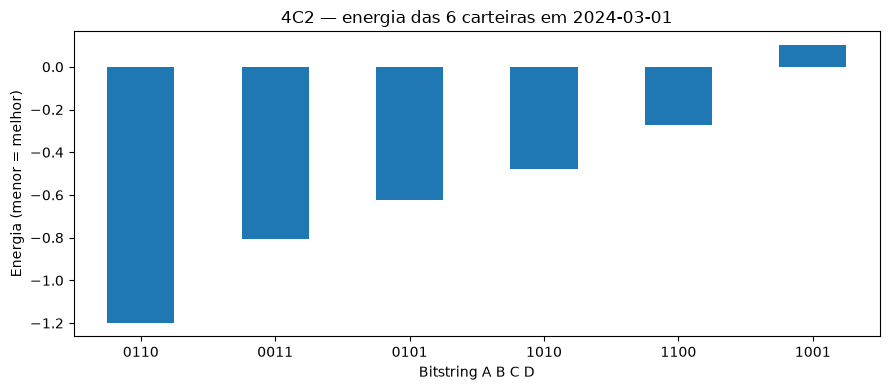

In [32]:
tab = tabela_carteiras(exemplo)
ax = tab.plot.bar(x='bitstring_ABCD', y='energia', figsize=(9, 4), legend=False)
ax.set(title=f'4C2 — energia das 6 carteiras em {exemplo["data"]}',
       xlabel='Bitstring A B C D', ylabel='Energia (menor = melhor)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Bloco C — Monte Carlo de contexto (engenharia de atributos)

### C1. O que são as 32 amostras de contexto?

**São sorteios clássicos**, realizados ANTES do Transformer. Não são medições de um circuito quântico.

- sorteamos 32 combinações válidas;
- calculamos sua energia com $(\mu,\Sigma)$;
- obtemos média, desvio-padrão e mínimo das 32 energias.

Esses três números são repetidos nos quatro tokens e informam a **escala do problema**.

**Limitação didática de 4C2:** existem apenas seis carteiras distintas! Portanto, 32 amostras quase sempre repetem escolhas e podem já encontrar o ótimo clássico. Isso torna o exemplo ideal para explicação, mas **inadequado para alegar vantagem de otimização**.

In [ ]:
def adicionar_contexto(r):
    chave = f"G538DEMO|{r['grupo']}|{r['data']}|{SEMENTE}"
    seed = int(hashlib.sha256(chave.encode()).hexdigest()[:8], 16)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(X), size=AMOSTRAS_CONTEXTO)
    escolhas = X[idx]                  # com reposição, como no pipeline original
    E = energias_de_carteiras(escolhas, r['mu'], r['Sigma'])
    r['contexto'] = {'X': escolhas, 'E': E,
                    'mean': float(E.mean()), 'std': float(E.std()),
                    'sample_min': float(E.min()), 'unique': len(set(idx))}

for r in INSTANCIAS:
    adicionar_contexto(r)
print('32 amostras, escolhas distintas:', exemplo['contexto']['unique'])

### C2. Visualizar o Monte Carlo clássico

**Entrada:** as 32 energias sorteadas na instância escolhida.

**Processamento:** histograma, média e melhor energia observada.

**Saída:** enxergamos concretamente de onde vêm os três atributos de contexto: `ctx_mean`, `ctx_std` e `ctx_min`.

In [ ]:
Ectx = exemplo['contexto']['E']
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(Ectx, bins=min(8, max(3, len(np.unique(Ectx)))), edgecolor='black')
ax.axvline(Ectx.mean(), ls='--', label='Média Monte Carlo')
ax.axvline(Ectx.min(), ls=':', label='Mínimo da amostra')
ax.set(xlabel='Energia das carteiras sorteadas', ylabel='Frequência',
       title='Monte Carlo clássico: 32 carteiras válidas')
ax.legend()
plt.tight_layout()
plt.show()

## Bloco D — Preparação do circuito de Dicke

### D1. Estado de Dicke: a base física da solução

Dicke em 4C2 é uma superposição com amplitudes iguais nas **seis** carteiras de dois ativos. Ele não usa $(\mu,\Sigma)$ e, por isso, não sabe qual carteira é financeiramente melhor.

$$|D_4^2\rangle=\frac1{\sqrt6}\sum_{x:\,|x|=2}|x\rangle.$$

**Entrada:** $n=4$, $k=2$.

**Saída:** $P_D(x)=1/6$ para toda carteira válida; esse ponto de partida será visualizado antes do Transformer.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(BITS, np.repeat(1 / len(X), len(X)))
ax.set(xlabel='Bitstrings A B C D', ylabel='Probabilidade',
       title='Dicke 4C2: as seis carteiras têm probabilidade 1/6')
ax.set_ylim(0, 0.23)
plt.tight_layout()
plt.show()

### D2. Listar os quatro gates e os ângulos de Dicke

O número de parâmetros do circuito é $g=k(n-k)=4$.

Para cada gate $j$, calculamos:

- índices $(i,l)$ dos qubits envolvidos;
- tipo `CY` ou `CCY`;
- período angular de referência;
- $\phi_{D,j}$, ângulo que prepara Dicke.

**Saída:** lista de quatro gates. Este é o esqueleto físico que não muda entre as datas financeiras.

In [ ]:
def portas_dicke(n, k):
    portas = []
    for l in range(n-1, -1, -1):
        for i in range(l-1, l-1-k, -1):
            if i < 0 or (l >= n-k and i >= n-k): continue
            tipo = 'CY' if i == l-1 else 'CCY'
            ang = (2 if tipo == 'CY' else 1) * np.arccos(np.sqrt((l-i)/(l+1)))
            periodo = 4*np.pi if tipo == 'CY' else 2*np.pi
            portas.append(dict(j=len(portas), i=i, l=l, tipo=tipo,
                                periodo=periodo, phiD=2*np.pi*ang/periodo))
    assert len(portas) == k*(n-k)
    return portas

PORTAS = portas_dicke(N, K)
PHI_D = np.array([p['phiD'] for p in PORTAS])
display(pd.DataFrame(PORTAS).round(5))

### D3. Gráfico — só os ângulos iniciais de Dicke

**Entrada:** `PORTAS`.

**Processamento:** representar $\phi_{D,j}$ versus o índice do gate.

**Saída:** gráfico que distingue o ponto inicial da posterior correção neural. Atenção: $\phi$ é uma coordenada angular normalizada do ansatz; o ângulo físico de uma rotação é $\theta_j=\phi_j T_j/(2\pi)$.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(range(len(PHI_D)), PHI_D, marker='o')
ax.set(xticks=range(len(PHI_D)), xticklabels=[f'j{j}' for j in range(len(PHI_D))],
       xlabel='Gate', ylabel=r'$\phi_{D,j}$', title='Dicke: ângulo inicial por gate')
plt.tight_layout()
plt.show()

## Bloco E — Engenharia de atributos do Transformer

### E1. Construir **exatamente os mesmos 18 atributos** do G5.38

Cada gate corresponde a uma linha de $T_H$. Em 4C2, o tensor cru é $T_H\in\mathbb R^{4\times18}$.

Os atributos 8 e 10 (indexação humana) descrevem a geometria de Dicke:

- $\phi_{D,j}/\pi$;
- $\sqrt{(l-i)/(l+1)}$.

Além disso, tipo de gate, período e posição dos qubits codificam outras propriedades da topologia. Os atributos financeiros informam os retornos e covariâncias **dos ativos associados aos índices $(i,l)$**. Os três últimos atributos são resumos do Monte Carlo de contexto.

**Saída:** matriz NumPy $4\times18$ de entradas financeiras, estruturais e de contexto.

In [ ]:
COLUNAS = ['j/(g-1)','n/(n+12)','k/n','i/(n-1)','l/(n-1)',
           'is_CY','is_CCY','phiD/pi','period/(4pi)','geom_Dicke',
           'mu_i','mu_l','var_i','var_l','cov_il',
           'ctx_mean','ctx_std','ctx_min']


def tokens_brutos(r):
    mu, cov, n, k, ctx = r['mu'], r['Sigma'], r['n'], r['k'], r['contexto']
    v = np.diag(cov)
    linhas = []
    for j, p in enumerate(PORTAS):
        i, l = p['i'], p['l']
        linhas.append([j/max(len(PORTAS)-1,1), n/(n+12), k/n,
            i/(n-1), l/(n-1), float(p['tipo']=='CY'), float(p['tipo']=='CCY'),
            p['phiD']/np.pi, p['periodo']/(4*np.pi), np.sqrt((l-i)/(l+1)),
            mu[i],mu[l],v[i],v[l],cov[i,l],
            ctx['mean'],ctx['std'],ctx['sample_min']])
    return np.asarray(linhas, dtype=np.float32)

### E2. Mostrar as 72 entradas brutas (quatro gates × 18 atributos)

**Entrada:** Hamiltoniano do cenário de treino e quatro gates.

**Processamento:** atribuir as 18 características a cada gate.

**Saída:** tabela com quatro linhas (uma por gate) e 18 colunas. Veja como características globais, como $k/n$, se repetem, enquanto retornos locais e índices mudam.

In [ ]:
RAW_4C2 = tokens_brutos(exemplo)
assert RAW_4C2.shape == (4, 18)
display(pd.DataFrame(RAW_4C2, columns=COLUNAS,
                     index=[f'gate j{j}' for j in range(4)]).round(5))

### E3. Padronizar corretamente sem consultar os testes

**Entrada:** tokens brutos das âncoras `treino_2024`.

**Processamento:** calcular média e desvio por coluna com **apenas 2024 de treinamento**. O `clip` limita valores padronizados ao intervalo $[-10,10]$ e evita entradas extremas.

$$z_{jh}=\operatorname{clip}\left(\frac{T_{jh}-m_h}{s_h},-10,10\right).$$

**Saída:** um normalizador de 18 colunas, ajustado apenas às datas de treino de 2024. A mesma média e desvio serão utilizados nas datas futuras, sem recalibração com dados de teste.

In [ ]:
RAW_TREINO = np.concatenate([tokens_brutos(r)
                              for r in POR_GRUPO['treino_2024']], axis=0)
MEDIA_DEMO = RAW_TREINO.mean(axis=0)
DESVIO_DEMO = np.maximum(RAW_TREINO.std(axis=0), 1e-5)

def padronizar(r, media, desvio):
    z = (tokens_brutos(r) - media) / desvio
    return np.clip(z, -10, 10).astype(np.float32)

print('Normalizador: somente âncoras de treino de 2024')

### E4. Mapa visual da entrada: quatro linhas × 18 colunas

**Entrada:** tokens padronizados de uma instância.

**Processamento:** colorir cada um dos 72 atributos.

**Saída:** imagem que mostra, literalmente, o tensor que o encoder receberá. No gráfico, as colunas de Dicke foram destacadas nos títulos; **não são ângulos aprendidos**.

In [ ]:
T_DEMO = padronizar(exemplo, MEDIA_DEMO, DESVIO_DEMO)
fig, ax = plt.subplots(figsize=(13, 3.6))
im = ax.imshow(T_DEMO, aspect='auto', cmap='coolwarm', vmin=-4, vmax=4)
ax.set_yticks(range(4), [f'gate j{j}' for j in range(4)])
ax.set_xticks(range(18), COLUNAS, rotation=60, ha='right', fontsize=8)
ax.set(title='Entrada do Transformer: tokens 4 × 18 (normalizados)')
fig.colorbar(im, ax=ax, label='Valor padronizado')
plt.tight_layout()
plt.show()

## Bloco F — Do token ao ângulo: o Transformer que será **treinado**

Cada gate $j$ possui um token $T_j\in\mathbb R^{18}$, contendo a geometria do circuito de Dicke e características financeiras do par de ativos.

O caminho computacional ativo da arquitetura original é preservado:

$$T_H\in\mathbb R^{4\times18}\;\longrightarrow\;\underbrace{Z\in\mathbb R^{4\times48}}_{\text{embedding + encoder}}\;\longrightarrow\;\underbrace{\Delta\phi\in\mathbb R^4}_{\text{cabeça angular}}.$$

A saída final do circuito é $\phi_j=\phi_{D,j}+\Delta\phi_j$. Os pesos da cabeça angular começam zerados, portanto a rede **começa exatamente em Dicke**.

Nesta demonstração, retiramos duas estruturas **inativas** do G5.38 (cabeça HF sem perda e adaptador alimentado com zeros). **A arquitetura ativa continua com dois blocos encoder, quatro cabeças de atenção, largura 48 e MLP 96.** Por isso, os novos checkpoints desta demonstração são independentes e não podem ser confundidos com os do G5.38 multicardinal.

In [ ]:
RHO = 1.2                            # limite das correções angulares, em unidades de phi

class EncoderOnly4C2(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed = nn.Sequential(nn.Linear(18, 48), nn.LayerNorm(48))
        camada = nn.TransformerEncoderLayer(d_model=48, nhead=4,
            dim_feedforward=96, dropout=0, activation='gelu', batch_first=True)
        self.encoder = nn.TransformerEncoder(camada, num_layers=2,
                                              enable_nested_tensor=False)
        self.angle = nn.Linear(48, 1)     # 48 informações → 1 correção por gate
        nn.init.zeros_(self.angle.weight) # início exato em Dicke
        nn.init.zeros_(self.angle.bias)

    def forward(self, tokens):
        h = self.embed(tokens)                       # 4 × 18 → 4 × 48
        z = self.encoder(h.unsqueeze(0)).squeeze(0)  # atenção conjunta dos 4 gates
        delta = RHO * torch.tanh(self.angle(z).squeeze(-1))
        return delta, z                             # 4 correções + representação 4 × 48

### F2. Primeiro, separar o experimento novo dos checkpoints históricos

**Entrada:** instâncias de treino/validação de 2024 e seus 18 atributos padronizados com estatísticas calculadas **somente no treino**.

**Saída:** configuração reprodutível da demonstração. O treinamento acontecerá **neste notebook**, sem depender de nenhum checkpoint do experimento multicardinal.

- `EPOCAS`: quantas passagens pela lista de Hamiltonianos de treino;
- `SPSA_DIRECOES`: número de pares de perturbações por atualização;
- `SHOTS_SPSA`: medições quânticas **de cada lado** ($+$ e $-$);
- `C_PERTURBACAO`: amplitude das perturbações de ângulo;
- `PASSO_ANGULAR`: distância do alvo local para ensinar o encoder;
- `TAXA_ADAMW`: taxa com que o otimizador ajusta os **pesos da rede**.

O custo de treinamento em shots será `atualizações × 2 × direções × shots por lado`.

In [ ]:
# O treino é obrigatório nesta versão demonstrativa: não reutilizar pesos anteriores.
SEED_TREINO = 11
EPOCAS = 5
SPSA_DIRECOES = 3
SHOTS_SPSA = 96
CVAR_ALPHA = 0.50                  # 4C2: evita saturação do CVaR10 de Dicke
C_PERTURBACAO = 0.12
PASSO_ANGULAR = 0.06
TAXA_ADAMW = 1e-3

DIR_TREINO = PASTA / 'treinamento_4c2_cvar50_spsa'
DIR_TREINO.mkdir(parents=True, exist_ok=True)
ARQ_PESOS_4C2 = DIR_TREINO / 'encoder4c2_melhor_validacao2024.pt'

torch.set_num_threads(min(4, torch.get_num_threads()))
print('Treino em 2024:', len(POR_GRUPO['treino_2024']), 'instâncias')
print('Validação 2024:', len(POR_GRUPO['validacao_2024']), 'instâncias')

### F3. Como obtemos a recompensa quântica sem conhecer os ângulos ótimos?

**Entrada:** quatro ângulos $\phi$ previstos pelo Transformer, uma instância financeira e uma semente de Monte Carlo.

**Processamento:**

1. construir o circuito completo com os quatro ângulos;
2. obter a distribuição $P_\phi(x)$ na **simulação ideal** de quatro qubits;
3. simular `SHOTS_SPSA` medições dessa distribuição;
4. converter cada bitstring amostrado em energia $E_H(x)$.

Não usamos o bitstring ótimo para ensinar o modelo. Ele só será usado na auditoria final. A rotina de circuito aparece detalhada no **Bloco G**; aqui usamos a mesma regra desde já para calcular a perda de treinamento.

In [ ]:
# Um gate é um bloco CY ou CCY, precedido e seguido de CX.
def construir_circuito(phi, ate=4):
    qc = QuantumCircuit(N)
    for q in (N-1, N-2): qc.x(q)  # inicializa |1100> (ordem de impressão Qiskit)
    for j, p in enumerate(PORTAS[:ate]):
        i, l = p['i'], p['l']
        theta = float(phi[j]) * p['periodo'] / (2*np.pi)
        qc.cx(i, l)
        if p['tipo'] == 'CY':
            qc.ry(theta/2, i); qc.cx(l, i)
            qc.ry(-theta/2, i); qc.cx(l, i)
        else:
            qc.ry(theta, i); qc.ccx(l, i+1, i)
            qc.ry(-theta, i); qc.ccx(l, i+1, i)
        qc.cx(i, l)
    return qc

### F4. A distribuição do circuito e a amostragem Monte Carlo

Este bloco calcula a probabilidade de cada uma das **seis** carteiras válidas. Para cada avaliação física, sorteamos bitstrings de acordo com essas probabilidades.

No simulador de vetor de estado, o vetor de probabilidades é computado exatamente e os *shots* são amostrados em Python. Isso equivale estatisticamente a medir repetidamente o **mesmo circuito ideal**, mas não representa erros de hardware.

Para reduzir o ruído da **diferença** $J^+-J^-$, usamos os mesmos números aleatórios uniformes nos dois lados da perturbação (técnica de números aleatórios comuns).

In [ ]:
INDICES_QISKIT = (X * (1 << np.arange(N))).sum(axis=1).astype(int)

def probs_circuito(phi):
    estado = Statevector.from_instruction(construir_circuito(phi))
    p = np.abs(np.asarray(estado.data))**2
    p = np.asarray(p[INDICES_QISKIT], dtype=float)
    assert abs(p.sum()-1) < 1e-9, 'O circuito saiu do subespaço de cardinalidade 2'
    return p / p.sum()


def energia_shots(phi, r, uniforme):
    p = probs_circuito(phi)
    indices = np.searchsorted(np.cumsum(p), uniforme, side='right').clip(max=len(p)-1)
    return energias_de_carteiras(X[indices], r['mu'], r['Sigma'])

### F5. Função de treinamento: CVaR dos melhores 50% das medições

Se medimos o circuito $B=96$ vezes, obtemos 96 energias. Ordenamos essas energias e calculamos a média das **48 menores**, pois $\lceil 0,50\times96\rceil=48$:

$$\widehat{\operatorname{CVaR}}_{50\%}=\frac{1}{48}\sum_{i=1}^{48} E_{(i)}.$$

A recompensa usada pelo SPSA é esse CVaR **normalizado** pela escala do contexto de 32 carteiras:

$$J(\phi;H)=\frac{\widehat{\operatorname{CVaR}}_{50\%}(\phi;H)-\bar E_{\rm contexto}}{\max(s_{\rm contexto},0,02)}.$$

O contexto estabiliza a escala entre datas diferentes. Subtrair uma constante de contexto **não muda** a diferença de CVaR entre os dois lados do SPSA para uma mesma instância.

**Por que 50% e não 10% neste único exemplo?** Em 4C2 há só 6 carteiras: Dicke já dá $1/6=16,67\%$ de probabilidade para a melhor. Portanto, o CVaR 10% da **distribuição exata** já é a energia ótima mesmo antes do treino; esse objetivo satura e não diferencia melhorias. Usamos 50% aqui para criar sinal de treinamento. **Isto não substitui o CVaR 10% validado nos experimentos multicardinais maiores.**

In [ ]:
def cvar_alpha(energias):
    valores = np.asarray(energias, dtype=float)
    m = max(1, math.ceil(CVAR_ALPHA * len(valores)))
    return float(np.partition(valores, m-1)[:m].mean())


def objetivo_cvar(energias, r):
    ctx = r['contexto']
    escala = max(float(ctx['std']), 0.02)
    return (cvar_alpha(energias)-float(ctx['mean']))/escala

assert np.isclose(cvar_alpha(np.arange(1, 97)), 24.5)
print('CVaR50 de 96 amostras: média das 48 menores = 24,5 (teste unitário)')

### F6. SPSA — a direção de melhora em quatro ângulos

O **SPSA** estima a direção do gradiente do objetivo sem derivar o circuito pelo PyTorch:

$$\hat g=\frac1D\sum_{d=1}^D\frac{J(\phi+c v_d)-J(\phi-c v_d)}{2c}\,v_d,$$

em que $v_d\in\{-1,+1\}^4$ é uma direção aleatória, $c$ é a amplitude de perturbação e $D=3$ é o número de direções.

- $J^+<J^-$ significa que, naquela direção, **aumentar** os ângulos reduziu o CVaR (melhorou o objetivo);
- a direção de atualização é $-\hat g/\|\hat g\|$, porque minimizamos energia;
- quando o gradiente é quase zero, evitamos inventar uma direção.

**Aqui está a ligação entre as medições Monte Carlo e o treinamento do Transformer.**

In [ ]:
def direcao_spsa(phi, r, rng):
    grad = np.zeros(len(phi), dtype=float)
    for _ in range(SPSA_DIRECOES):
        v = rng.choice([-1., 1.], size=len(phi))
        # Mesmos uniformes nos lados + e -: reduz variação da diferença.
        sorteios = rng.random(SHOTS_SPSA)
        Jmais = objetivo_cvar(energia_shots(phi+C_PERTURBACAO*v, r, sorteios), r)
        Jmenos = objetivo_cvar(energia_shots(phi-C_PERTURBACAO*v, r, sorteios), r)
        grad += (Jmais-Jmenos)*v/(2*C_PERTURBACAO)
    grad /= SPSA_DIRECOES
    norma = float(np.linalg.norm(grad))
    direcao = -grad/norma if norma > 1e-10 else np.zeros_like(grad)
    return direcao, norma

### F7. Como o gradiente SPSA atualiza os pesos? MSE local + AdamW

O SPSA não produz gradientes PyTorch dos pesos do Transformer. Ele indica uma **direção angular desejável** $d$.

Criamos um alvo temporário $\Delta\phi^{\rm alvo}=\operatorname{stopgrad}(\Delta\phi)+\eta d$ e minimizamos:

$$L_{\rm local}=\frac14\sum_{j=0}^{3}\left(\Delta\phi_j-\operatorname{stopgrad}(\Delta\phi^{\rm alvo}_j)\right)^2.$$

- `detach()` evita que o alvo acompanhe a própria previsão;
- `loss.backward()` calcula derivadas da MSE em relação aos **pesos** da rede;
- `AdamW.step()` altera efetivamente esses pesos;
- isto é aprendizado de um mapeamento de Hamiltoniano → ângulos, **não** otimização VQE iterativa durante o teste.

A MSE isolada não comprova aprendizagem: o que importa é melhorar o CVaR de validação e as probabilidades finais.

In [ ]:
def perda_direcional(delta, direcao):
    d = torch.as_tensor(direcao, dtype=delta.dtype, device=delta.device)
    alvo = (delta.detach() + PASSO_ANGULAR*d).detach()
    return torch.mean((delta-alvo)**2)

# Teste: a MSE deve promover deslocamento no sentido indicado pelo SPSA.
a = torch.tensor([0., 0., 0., 0.], requires_grad=True)
perda_direcional(a, [1., 0., 0., 0.]).backward()
assert a.grad[0] < 0  # gradiente negativo → passo do AdamW aumenta a primeira saída
print('A MSE local transmite o sinal angular para os pesos: OK')

### F8. Validação sem consultar o ótimo clássico

A seleção do checkpoint utiliza **somente agosto e setembro de 2024**.

Como 4C2 possui seis estados, podemos calcular a distribuição do circuito e o **CVaR exato da distribuição** sem recorrer à carteira ótima como rótulo de treino. Isso elimina o ruído de seleção de checkpoint causado por 96 shots.

- `cvar_exato`: calcula o percentil inferior de 50% ponderado pelas probabilidades dos seis estados;
- `minimo_esperado(probs, E, 1)`: desempate entre modelos com o mesmo CVaR, usando a energia média de um único shot;
- nenhum dos dois indicadores retroalimenta os testes de 2025 e 2026.

Essa é uma **validação metodologicamente distinta** do treinamento com CVaR amostrado.

In [ ]:
def cvar_exato(p, E, alpha=0.50):
    order = np.argsort(E)
    restante, soma = alpha, 0.
    for idx in order:
        peso = min(restante, float(p[idx]))
        soma += peso*float(E[idx])
        restante -= peso
        if restante <= 1e-12: break
    return soma/alpha


def minimo_esperado(p, E, B):
    order = np.argsort(E); e=np.asarray(E)[order]; q=np.asarray(p)[order]
    return float(e[0]+np.sum(np.diff(e)*(1-np.cumsum(q)[:-1])**B))

### F9. Executar o treinamento real: pesos antes → SPSA → AdamW → pesos depois

Para cada uma das `EPOCAS`, percorremos os Hamiltonianos de março a julho de 2024 em ordem aleatória. Cada instância provoca uma atualização dos pesos:

1. `modelo(tokens)` gera os quatro $\Delta\phi$;
2. somamos $\phi_D$ para obter os ângulos físicos;
3. SPSA avalia CVaR em $\phi\pm c v$, simulando os *shots*;
4. `perda_direcional` transforma a direção física em alvo local;
5. `backward` e `AdamW.step` aprendem pesos compartilhados entre todas as instâncias.

A cabeça angular começa zerada para que o **primeiro forward** reproduza exatamente Dicke. O treinamento é feito do zero neste notebook.

In [ ]:
import copy
import time

torch.manual_seed(SEED_TREINO)
MODELO = EncoderOnly4C2()
ESTADO_INICIAL = copy.deepcopy(MODELO.state_dict())
OTIMIZADOR = torch.optim.AdamW(MODELO.parameters(), lr=TAXA_ADAMW, weight_decay=1e-4)
RNG_TREINO = np.random.default_rng(SEED_TREINO)
TREINO = POR_GRUPO['treino_2024']
VALIDACAO = POR_GRUPO['validacao_2024']
HISTORICO = []
MELHOR_CVAR = np.inf
MELHOR_MIN1 = np.inf
MELHOR_EPOCA = None
MELHOR_ESTADO = None

assert len(TREINO) >= 20 and len(VALIDACAO) >= 4

### F10. Uma atualização dos pesos — linha por linha

Esta função é a parte mais importante da apresentação. Ela tem **uma única finalidade:** atualizar os pesos da rede para uma instância financeira.

- **Linha `MODELO(t)`**: um forward prevê quatro correções ao estado de Dicke.
- **Linha `direcao_spsa`**: as medições quânticas estimam como melhorar as correções.
- **Linha `perda.backward()`**: calculamos gradientes dos parâmetros do Transformer.
- **Linha `OTIMIZADOR.step()`**: os pesos são modificados.

O vetor $\phi$ calculado nesta função não é armazenado como parâmetro livre a ser otimizado na próxima instância; a rede aprende **a regra** que o produz.

In [ ]:
def atualizar_pesos(r):
    MODELO.train()
    OTIMIZADOR.zero_grad(set_to_none=True)
    t = torch.from_numpy(padronizar(r, MEDIA_DEMO, DESVIO_DEMO))
    delta, _ = MODELO(t)                         # 1. uma previsão dos quatro ângulos
    phi = PHI_D + delta.detach().numpy()         # 2. circuito ancorado em Dicke
    direcao, norma = direcao_spsa(phi, r, RNG_TREINO) # 3. sinal físico via MC + SPSA
    perda = perda_direcional(delta, direcao)     # 4. alvo local stop-gradient
    perda.backward()                            # 5. derivada da MSE em relação aos pesos
    nn.utils.clip_grad_norm_(MODELO.parameters(), 1.)
    OTIMIZADOR.step()                            # 6. atualiza os pesos do Transformer
    return float(perda.detach()), norma

### F11. Avaliar cada época separadamente, sem reajustar a rede

Ao fim de cada época, usamos os mesmos conjuntos fixos de treino e validação para acompanhar o **CVaR exato médio**. A validação fica em 2024; o modelo não recebe gradientes dos exemplos de validação.

A energia é normalizada com os **32 exemplos de contexto de cada Hamiltoniano** para comparar diferentes escalas financeiras.

Ao final, o checkpoint de menor CVaR de validação é salvo. Se o CVaR empatar numericamente, usamos o mínimo esperado em 1 shot apenas como desempate **de validação**, não de teste.

In [ ]:
@torch.no_grad()
def avaliar_grupo(instancias):
    MODELO.eval()
    dados = []
    for r in instancias:
        tok = torch.from_numpy(padronizar(r, MEDIA_DEMO, DESVIO_DEMO))
        delta, _ = MODELO(tok)
        probs = probs_circuito(PHI_D + delta.numpy())
        E = energias_de_carteiras(X, r['mu'], r['Sigma'])
        s = max(float(r['contexto']['std']), 0.02)
        cvar = (cvar_exato(probs, E)-r['contexto']['mean'])/s
        minimo1 = (minimo_esperado(probs, E, 1)-r['contexto']['mean'])/s
        dados.append((cvar, minimo1))
    return np.mean(dados, axis=0)

### F12. Rodar as épocas e salvar o checkpoint escolhido por validação

Esta é a célula que efetivamente treina. A barra de progresso aparece a cada época; o tempo dependerá da CPU porque o circuito 4C2 é simulado muitas vezes.

**Orçamento:** $N_{\rm atualizações}=\text{EPOCAS}\times|\text{TREINO}|$ e
$N_{\rm shots}=N_{\rm atualizações}\times2\times3\times96$.

Os checkpoints próprios desta demonstração são gravados na pasta `treinamento_4c2_cvar50_spsa`, **sem sobrescrever** os do G5.38 original.

In [ ]:
INICIO_TREINO = time.perf_counter()
for epoca in range(1, EPOCAS+1):
    perdas, normas = [], []
    for indice in RNG_TREINO.permutation(len(TREINO)):
        perda, norma = atualizar_pesos(TREINO[int(indice)])
        perdas.append(perda); normas.append(norma)
    tr_cvar, tr_m1 = avaliar_grupo(TREINO)
    va_cvar, va_m1 = avaliar_grupo(VALIDACAO)
    HISTORICO.append(dict(epoca=epoca, treino_cvar=tr_cvar, validacao_cvar=va_cvar,
                          treino_min1=tr_m1, validacao_min1=va_m1,
                          perda_local=np.mean(perdas), gradientes_nulos=np.mean(np.array(normas)<1e-10)))
    if va_cvar < MELHOR_CVAR-1e-8 or (abs(va_cvar-MELHOR_CVAR)<1e-8 and va_m1 < MELHOR_MIN1):
        MELHOR_CVAR, MELHOR_MIN1 = float(va_cvar), float(va_m1)
        MELHOR_EPOCA, MELHOR_ESTADO = epoca, copy.deepcopy(MODELO.state_dict())
    print(f'Época {epoca}/{EPOCAS} | CVaR treino={tr_cvar:.4f} | '
          f'CVaR validação={va_cvar:.4f} | melhor época={MELHOR_EPOCA}', flush=True)

MODELO.load_state_dict(MELHOR_ESTADO)
MODELO.eval()
MODELO_TREINADO = True
torch.save(MELHOR_ESTADO, ARQ_PESOS_4C2)
np.savez(DIR_TREINO/'normalizador_apenas_treino2024.npz',
         mean=MEDIA_DEMO, std=DESVIO_DEMO)
PD_HIST = pd.DataFrame(HISTORICO)
PD_HIST.to_csv(DIR_TREINO/'historico_2024.csv', index=False)
print('Duração (s):', round(time.perf_counter()-INICIO_TREINO, 1))
print('Total de shots SPSA:', EPOCAS*len(TREINO)*2*SPSA_DIRECOES*SHOTS_SPSA)

### F13. Gráficos do treinamento e da validação de 2024

**Gráfico 1:** evolução do CVaR normalizado (menor é melhor) para treino e validação. Aqui vemos se aprender em março–julho ajuda nas datas de agosto–setembro.

**Gráfico 2:** mínimo esperado em 1 shot, que é sensível à distribuição mesmo quando o CVaR satura nos melhores estados.

**Não desenhamos uma curva de testes de 2025–2026 por época:** isso contaminaria o processo de seleção. Os testes serão apresentados só depois de congelarmos o modelo.

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for eixo, sufixo, titulo in [(ax[0], 'cvar', 'CVaR 50% exato'),
                             (ax[1], 'min1', 'Energia média esperada — 1 shot')]:
    eixo.plot(PD_HIST.epoca, PD_HIST[f'treino_{sufixo}'], '-o', label='Treino 2024')
    eixo.plot(PD_HIST.epoca, PD_HIST[f'validacao_{sufixo}'], '-s', label='Validação 2024')
    eixo.axvline(MELHOR_EPOCA, ls=':', color='gray', label='checkpoint selecionado')
    eixo.set(xlabel='Época', ylabel='Energia normalizada', title=titulo)
    eixo.legend(fontsize=8)
fig.tight_layout()
plt.show()

### F14. Auditoria do aprendizado: como os pesos e os ângulos mudaram?

Vamos reconstruir uma rede **antes do treinamento**, a partir da cópia dos pesos iniciais, e compará-la com o melhor checkpoint aprendido.

- **Antes:** a cabeça final tem pesos nulos, logo $\Delta\phi=0$ e o circuito reproduz Dicke.
- **Depois:** a rede pode produzir $\Delta\phi\ne0$ para o Hamiltoniano financeiro.
- **Evidência física:** além de mostrar diferenças nos pesos e ângulos, compararemos a probabilidade do ótimo em 2024 e nos testes futuros.

In [ ]:
MODELO_ANTES = EncoderOnly4C2().eval()
MODELO_ANTES.load_state_dict(ESTADO_INICIAL)

with torch.no_grad():
    T_EXEMPLO = torch.from_numpy(padronizar(exemplo, MEDIA_DEMO, DESVIO_DEMO))
    DELTA_ANTES, _ = MODELO_ANTES(T_EXEMPLO)
    DELTA_DEPOIS, _ = MODELO(T_EXEMPLO)

assert np.allclose(DELTA_ANTES.numpy(), 0, atol=1e-9)
print('Correções antes:', DELTA_ANTES.numpy().round(5))
print('Correções depois:', DELTA_DEPOIS.numpy().round(5))
print('Checkpoint selecionado pela validação na época:', MELHOR_EPOCA)

### F15. Congelar os pesos depois do treinamento

**Entrada:** modelo escolhido pelo CVaR de validação de 2024.

**Processamento:** mudar para modo de inferência (`eval`) e reutilizar o normalizador de treino. **Nenhuma chamada a `AdamW.step()` ocorre nos testes.**

**Saída:** um Transformer que retorna quatro correções angulares por Hamiltoniano em um único forward.

In [ ]:
modelo = MODELO.eval()                  # melhor checkpoint recém-treinado
MEDIA_USADA = MEDIA_DEMO.copy()         # calculada SOMENTE com treino 2024
DESVIO_USADO = DESVIO_DEMO.copy()

print('Modelo treinado:', MODELO_TREINADO)
print('Checkpoint:', ARQ_PESOS_4C2)

### F16. Conferir as dimensões internas do Transformer treinado

**Entrada:** matriz $T_H\in\mathbb R^{4\times18}$ do Hamiltoniano de demonstração.

**Saída do encoder:** quatro vetores de 48 números, um vetor por gate. A atenção conecta os tokens; a rede **não** simula um estado quântico intermediário.

**Saída da cabeça:** quatro correções $\Delta\phi_j$, uma para cada gate. Elas são previstas **simultaneamente**, não uma depois da outra.

In [ ]:
T = padronizar(exemplo, MEDIA_USADA, DESVIO_USADO)
tensor = torch.from_numpy(T)
with torch.no_grad():
    delta, representacoes_48 = modelo(tensor)

print('Entrada:', tuple(tensor.shape))
print('Representações do encoder:', tuple(representacoes_48.shape))
print('Correções angulares:', tuple(delta.shape))

### F17. Construir os ângulos finais a partir de Dicke

O modelo não precisa calcular ângulos do zero:

$$\boxed{\phi_j=\phi_{D,j}+\Delta\phi_j},$$

com $\Delta\phi_j=\rho\tanh(a_j)$.

**Entrada:** quatro ângulos de Dicke e quatro correções neurais.

**Processamento:** soma residual posição a posição.

**Saída:** exatamente quatro ângulos para os quatro gates de 4C2. O modelo já foi treinado e o melhor checkpoint foi escolhido em validação de 2024; na configuração inicial, antes do treino, teríamos $\Delta\phi=0$.

In [ ]:
DELTA = delta.detach().cpu().numpy()
PHI_FINAL = PHI_D + DELTA

angulos = pd.DataFrame({'gate':[f'j{j}' for j in range(4)],
                        'phi_Dicke':PHI_D, 'delta_prevista':DELTA,
                        'phi_final':PHI_FINAL})
display(angulos.round(6))

### F18. Gráfico dos ângulos: base, correção e configuração final

**Entrada:** ângulos anteriores.

**Saída:** gráfico que explica visualmente a soma residual. **As curvas dos ângulos corrigidos representam o modelo treinado do zero neste notebook, selecionado pela validação de 2024.**

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = range(len(PHI_D))
ax.plot(x, PHI_D, 'o-', label='Dicke: phi_D')
ax.plot(x, DELTA, 's--', label='Correção: Delta phi')
ax.plot(x, PHI_FINAL, '^-', label='Final: phi_D + Delta phi')
ax.set(xticks=list(x), xticklabels=[f'j{j}' for j in x],
       xlabel='Gate', ylabel='Coordenada angular phi',
       title='Predição residual dos quatro gates')
ax.legend()
plt.tight_layout()
plt.show()

## Bloco G — O circuito quântico, gate a gate

### G1. Construir **o mesmo ansatz de Dicke** do projeto

**Entrada:** lista de gates e seus ângulos finais $\phi_j$.

**Processamento:** executar a sequência na ordem $j_0\to j_1\to j_2\to j_3$.

O código usa decomposições controladas que reproduzem as operações `CY`/`CCY` do projeto.

**Saída:** circuito Qiskit com o estado preparado após `ate` gates. Não existe atualização do Transformer dentro desse `for`: toda a previsão já ocorreu.

In [ ]:
def circuito_ate(phi, ate=4):
    # Reutiliza os EXATOS blocos de portas que foram usados no treino.
    # ate=0 é o estado inicial; ate=1 inclui apenas j0; ate=4 inclui todos.
    return construir_circuito(phi, ate=ate)


### G2. Desenho do circuito no terminal Jupyter

**Entrada:** configuração de Dicke (sem correção) e sequência de gates.

**Saída:** desenho textual real produzido por Qiskit, com cada `CX`, `RY` e `CCX` da decomposição. Para não exigir `pylatexenc`, usamos `draw('text')`.

In [ ]:
print('Circuito completo de preparação do estado de Dicke 4C2:')
print(circuito_ate(PHI_D).draw('text'))

### G3. Evolução física: antes, após $j_0$, após $j_1$, ...

**Entrada:** os ângulos de Dicke; **não os do Transformer**, para que possamos isolar o que Dicke constrói.

**Processamento:** calcular o vetor de estado ideal após cada prefixo da sequência.

**Saída:** gráfico com cinco painéis. Ao final, as seis carteiras válidas recebem probabilidade $1/6$.

**Convenção:** internamente `q0` representa A, mas o Qiskit imprime os bits na ordem `q3 q2 q1 q0`. Converteremos os índices para a ordem financeira A-B-C-D antes de mostrar.

**Não há dois circuitos diferentes:** o código de visualização abaixo chama a mesma função `construir_circuito` usada pelo SPSA durante o treinamento. Isso permite inspecionar o estado após cada gate sem mudar a física do experimento.

In [ ]:
def distribuicao_valida(phi, ate=4):
    sv = Statevector.from_instruction(circuito_ate(phi, ate))
    probabilidades = np.abs(sv.data)**2
    indices_qiskit = (X * (1 << np.arange(N))).sum(axis=1).astype(int)
    massa = probabilidades[indices_qiskit]
    erro_fora = 1.0 - float(massa.sum())
    if abs(erro_fora) > 1e-9:
        raise AssertionError(f'Estados inválidos no circuito: {erro_fora}')
    return massa

PROBS_DICKE = [distribuicao_valida(PHI_D, ate) for ate in range(5)]
assert np.allclose(PROBS_DICKE[-1], 1/6, atol=1e-9)
print('Dicke uniforme em 4C2: verificação matemática aprovada')

### G4. Visualizar as cinco distribuições de Dicke

**Entrada:** estados calculados após cada gate.

**Saída:** cinco gráficos lado a lado, exibindo a transferência de probabilidade a cada passo. No último painel, o estado de Dicke estará uniforme.

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.5), sharey=True)
rotulos = ['Inicial', 'Após j0', 'Após j1', 'Após j2', 'Após j3']
for ax, ps, titulo in zip(axes, PROBS_DICKE, rotulos):
    ax.bar(BITS, ps)
    ax.set(title=titulo, ylim=(0,1.05))
    ax.tick_params(axis='x', rotation=90)
axes[0].set_ylabel('Probabilidade')
fig.suptitle('Construção do estado de Dicke: evolução sequencial dos gates')
plt.tight_layout()
plt.show()

## Bloco H — Comparar o circuito antes e depois do treinamento

A distribuição de Dicke é uniforme entre os seis estados. O modelo treinado deve modificar essa distribuição **sem violar a cardinalidade 4C2**.

O gráfico abaixo compara:

- **Dicke / rede antes:** probabilidades $1/6$ por carteira;
- **rede depois:** probabilidades da configuração angular aprendida;
- **ótimo clássico:** identificado por enumeração somente para **auditoria**, sem servir como rótulo de treinamento.

Se não houver melhora no exemplo, isso será mostrado explicitamente: **não estamos impondo o resultado esperado**.

In [ ]:
P_DICKE = distribuicao_valida(PHI_D)
P_MODELO = distribuicao_valida(PHI_FINAL)
E_EXEMPLO = energias_de_carteiras(X, exemplo['mu'], exemplo['Sigma'])
i_otimo_demo = int(np.argmin(E_EXEMPLO))

fig, ax = plt.subplots(figsize=(9, 4))
u = np.arange(len(BITS))
ax.bar(u-.18, P_DICKE, width=.36, label='Antes: Dicke')
ax.bar(u+.18, P_MODELO, width=.36, label='Depois: Transformer treinado')
ax.axvline(i_otimo_demo, color='red', lw=1.3, ls=':', label='ótimo clássico')
ax.set(xticks=u, xticklabels=BITS, xlabel='Bitstring A B C D',
       ylabel='Probabilidade', title='4C2 — antes × depois do aprendizado')
ax.legend(); plt.tight_layout(); plt.show()

### H2. Onde entra o segundo Monte Carlo?

Agora realizamos **128 medições simuladas** da **mesma distribuição final**. Elas não recalculam nem reotimizam os quatro ângulos.

No computador, como temos o vetor de estado exato, `rng.choice` reproduz estatisticamente os resultados que obteríamos ao medir esse estado ideal 128 vezes. Isso **não representa ruído de hardware real**.

**Entrada:** seis probabilidades finais.

**Saída:** 128 bitstrings medidos, suas frequências e as energias correspondentes.

In [ ]:
SHOTS = 128
rng_shots = np.random.default_rng(SEMENTE + 1)
observados = rng_shots.choice(len(X), size=SHOTS, p=P_MODELO)
frequencias = np.bincount(observados, minlength=len(X))

print('Forward do Transformer: 1')
print('Configurações angulares: 1')
print('Medições simuladas: ', SHOTS)
display(pd.DataFrame({'bitstring': BITS,
                      'frequencia': frequencias,
                      'proporcao': frequencias / SHOTS}))

### H3. Converter os bitstrings medidos em carteiras e energias

**Entrada:** índices observados nas 128 medições.

**Processamento:** calcular as energias das carteiras observadas e escolher a menor.

**Saída:** uma carteira selecionada pelas medições e uma comparação com a resposta exata do pequeno problema 4C2.

**Importante:** os shots são sorteios da distribuição produzida pelo modelo treinado. A distribuição de Dicke permanece como referência, mas nenhum novo peso é aprendido nessa etapa.

In [ ]:
E_TODAS = energias_de_carteiras(X, exemplo['mu'], exemplo['Sigma'])
i_melhor_obs = int(observados[np.argmin(E_TODAS[observados])])
i_otimo = int(np.argmin(E_TODAS))

print('Melhor bitstring medido:', BITS[i_melhor_obs])
print('Energia observada:', round(float(E_TODAS[i_melhor_obs]), 6))
print('Ótimo clássico exato:', BITS[i_otimo])
print('Energia do ótimo:', round(float(E_TODAS[i_otimo]), 6))
print('Acertou o ótimo?', bool(i_melhor_obs == i_otimo))

### H4. Visualizar o fluxo completo: engenharia de dados → inferência → medições

**Entrada:** nenhuma nova variável; é um diagrama explicativo.

**Saída:** mapa do pipeline para projetar na apresentação. **Monte Carlo de contexto (32 carteiras) e amostragem do circuito (128 shots) são operações diferentes.**

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.axis('off')
blocos = [
    ('Yahoo\npreços', .04), ('Engenharia\nretornos, mu, Sigma', .22),
    ('MC clássico\n32 carteiras', .43), ('Dicke + tokens\n4 × 18', .63),
    ('Encoder\n4 × 48 → 4 phi', .83),
]
for texto, x in blocos:
    ax.text(x, .65, texto, transform=ax.transAxes, va='center', ha='center',
            bbox=dict(boxstyle='round,pad=.7', fc='#dbeafe', ec='#64748b'))
for x in (.125,.325,.525,.735):
    ax.annotate('', xy=(x+.045,.65), xytext=(x-.01,.65),
                xycoords='axes fraction', textcoords='axes fraction',
                arrowprops=dict(arrowstyle='->', lw=1.5))
ax.text(.85, .20, 'Circuito 4 gates → 128 shots → bitstrings → energia',
        ha='center', fontsize=11, transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=.7', fc='#d1fae5', ec='#64748b'))
ax.annotate('', xy=(.85,.29), xytext=(.85,.52),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='->', lw=1.5))
plt.show()

## Bloco I — Testar o modelo **sem alterar os pesos**

O modelo terminou de treinar e seu melhor checkpoint já foi selecionado em 2024. Agora aplicamos os mesmos pesos e o mesmo normalizador aos Hamiltonianos de:

- **Treino:** março–julho/2024;
- **Validação:** agosto–setembro/2024;
- **Teste 2025:** junho/dezembro/2025;
- **Teste 2026:** junho/setembro/2026.

Em 4C2, sabemos a resposta clássica porque enumeramos as **seis** carteiras. Usaremos esse ótimo exclusivamente para verificar se a distribuição do circuito lhe atribui probabilidade maior que o Dicke uniforme ($1/6$).

O teste possui somente duas âncoras por ano e os quatro ativos permanecem iguais; portanto, é uma **demonstração temporal**, não um estudo estatístico robusto.

In [ ]:
quadro = pd.DataFrame([{
    'grupo': r['grupo'], 'data': r['data'],
    'mu_A': r['mu'][0], 'sigma_AB': r['Sigma'][0,1],
    'contexto_min': r['contexto']['sample_min']
} for r in INSTANCIAS])
display(quadro.round(5))

### I2. Mostrar que o tensor continua sendo $4\times18$ em outros anos

**Entrada:** um problema de validação 2024 e problemas de teste de 2025/2026.

**Processamento:** criar tokens sem recalcular média/desvio nos anos futuros.

**Saída:** mesmas dimensões, porém valores financeiros diferentes. A geometria de Dicke permanece fixa porque a topologia continua 4C2.

In [ ]:
for grupo in ('treino_2024','validacao_2024','teste_2025','teste_2026'):
    r = POR_GRUPO[grupo][0]
    tokens = padronizar(r, MEDIA_USADA, DESVIO_USADO)
    print(f'{grupo:16s} | {r["data"]} | {tokens.shape}')
    assert tokens.shape == (4,18)

### I3. Testes reais de 2025/2026: probabilidades do ótimo, antes e depois

**Entrada:** quatro grupos temporais; o mesmo modelo treinado, sem atualizar pesos.

**Processamento:** para cada Hamiltoniano, calcular a distribuição ideal da rede; encontrar por enumeração clássica o bitstring de menor energia; ler a probabilidade atribuída a esse bitstring.

**Saída:** três indicadores facilmente explicáveis:

- **$p_*$:** chance de medir o ótimo em um único shot;
- **$P_{16}=1-(1-p_*)^{16}$:** chance de vê-lo em até 16 shots;
- **$P_{128}$:** chance de vê-lo em até 128 shots.

São **probabilidades analíticas da simulação ideal**, não taxas observadas de hardware quântico.

In [ ]:
@torch.no_grad()
def avaliar_probabilidade_otimo(r):
    token = torch.from_numpy(padronizar(r, MEDIA_USADA, DESVIO_USADO))
    delta, _ = modelo(token)           # apenas um forward, pesos congelados
    p = probs_circuito(PHI_D + delta.numpy())
    E = energias_de_carteiras(X, r['mu'], r['Sigma'])
    melhor = int(np.argmin(E))         # auditoria: nunca entra na entrada da rede
    p_opt = float(p[melhor])
    return dict(grupo=r['grupo'], data=r['data'], bitstring_otimo=BITS[melhor],
                p_dicke=1/len(X), p_transformer=p_opt,
                acerto16=1-(1-p_opt)**16, acerto128=1-(1-p_opt)**128,
                energia_otima=float(E[melhor]))

### I4. Tabela da avaliação final e gráfico treino–validação–teste

A tabela apresenta todas as âncoras temporais. Para facilitar a leitura, o gráfico mostra **médias por período**. Os dois grupos de teste têm somente duas âncoras cada; seus valores não devem ser interpretados como intervalos estatísticos estreitos.

**Linha horizontal Dicke:** 16,67% por shot em 4C2.

**Barras do Transformer:** probabilidade do ótimo calculada com os pesos aprendidos em 2024.

Um ganho em $p_*$ mostra que o circuito concentra mais probabilidade no melhor bitstring; não demonstra que o Transformer recebeu a resposta ótima como rótulo.

In [ ]:
AVALIACAO_FINAL = pd.DataFrame([avaliar_probabilidade_otimo(r) for r in INSTANCIAS])
ORDEM_GRUPOS = ['treino_2024', 'validacao_2024', 'teste_2025', 'teste_2026']
MEDIAS = AVALIACAO_FINAL.groupby('grupo')[['p_dicke', 'p_transformer',
                                             'acerto16', 'acerto128']].mean().loc[ORDEM_GRUPOS]
display(AVALIACAO_FINAL.round(5))
display(MEDIAS.round(5))

fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(MEDIAS))
ax.bar(x-.19, MEDIAS.p_dicke, .38, label='Antes: Dicke')
ax.bar(x+.19, MEDIAS.p_transformer, .38, label='Depois: Transformer')
ax.set(xticks=x, xticklabels=['Treino 2024', 'Validação 2024', 'Teste 2025', 'Teste 2026'],
       ylabel='Probabilidade média do ótimo em 1 shot', ylim=(0,1))
ax.legend(); ax.set_title('4C2 — Generalização temporal da distribuição aprendida')
plt.tight_layout(); plt.show()

### I5. Conferir a amplitude da mudança da rede

Além do resultado final, vamos mostrar se os pesos **realmente mudaram** após o treinamento.

Uma alteração de pesos é necessária para aprendizagem, mas não é suficiente para afirmar que o método melhorou. Por isso, o indicador principal permanece a qualidade da distribuição em treino, validação e teste.

In [ ]:
PESOS_DEPOIS = modelo.state_dict()
DESLOCAMENTOS = {nome: float(torch.linalg.norm(PESOS_DEPOIS[nome]-ESTADO_INICIAL[nome]))
                 for nome in PESOS_DEPOIS}
print('Norma da mudança dos pesos da cabeça angular:', round(DESLOCAMENTOS['angle.weight'], 6))
print('Norma da mudança do embedding:', round(DESLOCAMENTOS['embed.0.weight'], 6))
print('Quantidade de épocas:', EPOCAS)
print('Checkpoint validado pela época:', MELHOR_EPOCA)

## Conclusões para a apresentação: o que provamos e o que ainda não provamos?

1. **Engenharia de dados real:** os preços históricos do Yahoo Finance são transformados em retornos, $\mu$, $\Sigma$ e 18 atributos por gate.
2. **Dicke:** o circuito começa em uma distribuição uniforme sobre os seis estados válidos de 4C2.
3. **Transformer:** quatro tokens são convertidos em quatro representações de 48 dimensões e quatro correções angulares.
4. **Treinamento realizado neste notebook:** SPSA usa medições simuladas para estimar uma direção física; MSE + AdamW atualizam os pesos da rede.
5. **Inferência one-forward:** um forward produz quatro ângulos; o circuito aplica os gates sequencialmente e as medições sorteiam carteiras.
6. **Validação honesta:** checkpoint escolhido exclusivamente em 2024. Os testes retrospectivos 2025–2026 ficam congelados para a apresentação final.

**Limitações:** 4C2 tem somente seis resultados possíveis, utiliza janelas financeiras sobrepostas e não contempla ruído de hardware. Mesmo que a probabilidade do ótimo melhore, isso **não** demonstra vantagem quântica ou escalabilidade para 40 qubits.